In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
df = pd.read_csv("Marketing_Campaign_Cleaned.csv")

In [3]:
df.head()

,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Campaign_Tag,Conversions_Missing,Start_Date_Missing,Campaign_Duration_Days,CTR_%,Conversion_Rate_%
0,CMP-00001,Q4_Summer_CMP-00001,24-11-2023,13-12-2023,TikTok,16795,197,102.82,20.0,True,TI,False,False,19.0,1.172968,10.152284
1,CMP-00002,Q1_Launch_CMP-00002,06-05-2023,12-05-2023,Facebook,1860,30,24.33,1.0,False,FA,False,False,6.0,1.612903,3.333333
2,CMP-00003,Q3_Winter_CMP-00003,13-12-2023,20-12-2023,Email,77820,843,1323.39,51.0,False,EM,False,False,7.0,1.083269,6.049822
3,CMP-00004,Q1_BlackFriday_CMP-00004,30-10-2023,03-11-2023,TikTok,55886,2019,2180.38,135.0,True,TI,False,False,4.0,3.612712,6.686478
4,CMP-00005,Q2_Winter_CMP-00005,22-04-2023,23-04-2023,Facebook,7265,169,252.44,30.0,True,FA,False,False,1.0,2.326222,17.751479


In [4]:
df.shape

(100, 16)

In [5]:
df.columns

Index(['Campaign_ID', 'Campaign_Name', 'Start_Date', 'End_Date', 'Channel',
       'Impressions', 'Clicks', 'Spend', 'Conversions', 'Active',
       'Campaign_Tag', 'Conversions_Missing', 'Start_Date_Missing',
       'Campaign_Duration_Days', 'CTR_%', 'Conversion_Rate_%'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Campaign_ID             100 non-null    str    
 1   Campaign_Name           100 non-null    str    
 2   Start_Date              99 non-null     str    
 3   End_Date                100 non-null    str    
 4   Channel                 100 non-null    str    
 5   Impressions             100 non-null    int64  
 6   Clicks                  100 non-null    int64  
 7   Spend                   100 non-null    float64
 8   Conversions             90 non-null     float64
 9   Active                  100 non-null    bool   
 10  Campaign_Tag            100 non-null    str    
 11  Conversions_Missing     100 non-null    bool   
 12  Start_Date_Missing      100 non-null    bool   
 13  Campaign_Duration_Days  96 non-null     float64
 14  CTR_%                   100 non-null    float64
 15  C

In [7]:
df.describe()

,Impressions,Clicks,Spend,Conversions,Campaign_Duration_Days,CTR_%,Conversion_Rate_%
count,100.000000,100.000000,100.000000,90.000000,96.000000,100.000000,90.000000
mean,52401.580000,1490.850000,1942.803900,176.700000,18.708333,2.829166,11.609623
std,28762.687103,1000.995498,1478.699808,145.811981,32.897262,1.013623,4.698091
min,1769.000000,30.000000,24.330000,1.000000,1.000000,1.034670,3.333333
25%,26318.500000,798.250000,657.915000,55.750000,8.000000,1.993689,7.102281
50%,57238.500000,1326.000000,1741.635000,148.500000,14.000000,2.786240,10.738914
75%,75686.750000,2313.250000,2770.377500,250.500000,20.000000,3.515296,16.064705
max,97276.000000,4046.000000,5951.420000,567.000000,285.000000,4.967581,19.263804


In [8]:
df.isnull().sum()

Campaign_ID                0
Campaign_Name              0
Start_Date                 1
End_Date                   0
Channel                    0
Impressions                0
Clicks                     0
Spend                      0
Conversions               10
Active                     0
Campaign_Tag               0
Conversions_Missing        0
Start_Date_Missing         0
Campaign_Duration_Days     4
CTR_%                      0
Conversion_Rate_%         10
dtype: int64

In [9]:
df["Calculated_CTR_%"] = (
    df["Clicks"] / df["Impressions"].replace(0, np.nan)
) * 100

df["Calculated_Conversion_Rate_%"] = (
    df["Conversions"] / df["Clicks"].replace(0, np.nan)
) * 100

df["CPC"] = (
    df["Spend"] / df["Clicks"].replace(0, np.nan)
)

df["CPA"] = (
    df["Spend"] / df["Conversions"].replace(0, np.nan)
)

df["CPM"] = (
    df["Spend"] / df["Impressions"].replace(0, np.nan)
) * 1000

In [10]:
df[[
    "Campaign_Name",
    "Impressions",
    "Clicks",
    "Spend",
    "Conversions",
    "Calculated_CTR_%",
    "Calculated_Conversion_Rate_%",
    "CPC",
    "CPA",
    "CPM"
]].head(10)

,Campaign_Name,Impressions,Clicks,Spend,Conversions,Calculated_CTR_%,Calculated_Conversion_Rate_%,CPC,CPA,CPM
0,Q4_Summer_CMP-00001,16795,197,102.82,20.0,1.172968,10.152284,0.521929,5.141000,6.122060
1,Q1_Launch_CMP-00002,1860,30,24.33,1.0,1.612903,3.333333,0.811000,24.330000,13.080645
2,Q3_Winter_CMP-00003,77820,843,1323.39,51.0,1.083269,6.049822,1.569858,25.948824,17.005783
3,Q1_BlackFriday_CMP-00004,55886,2019,2180.38,135.0,3.612712,6.686478,1.079931,16.150963,39.014780
4,Q2_Winter_CMP-00005,7265,169,252.44,30.0,2.326222,17.751479,1.493728,8.414667,34.747419
5,Q4_BlackFriday_CMP-00006,83386,2643,2697.03,NaN,3.169597,NaN,1.020443,NaN,32.343919
6,Q3_Launch_CMP-00007,38194,1135,1232.76,178.0,2.971671,15.682819,1.086132,6.925618,32.276274
7,Q4_Launch_CMP-00008,88498,1173,865.70,127.0,1.325454,10.826939,0.738022,6.816535,9.782142
8,Q4_BlackFriday_CMP-00009,45131,1179,1046.18,104.0,2.612395,8.821035,0.887345,10.059423,23.180962
9,Q2_Winter_CMP-00010,61263,1153,1623.56,NaN,1.882050,NaN,1.408118,NaN,26.501477


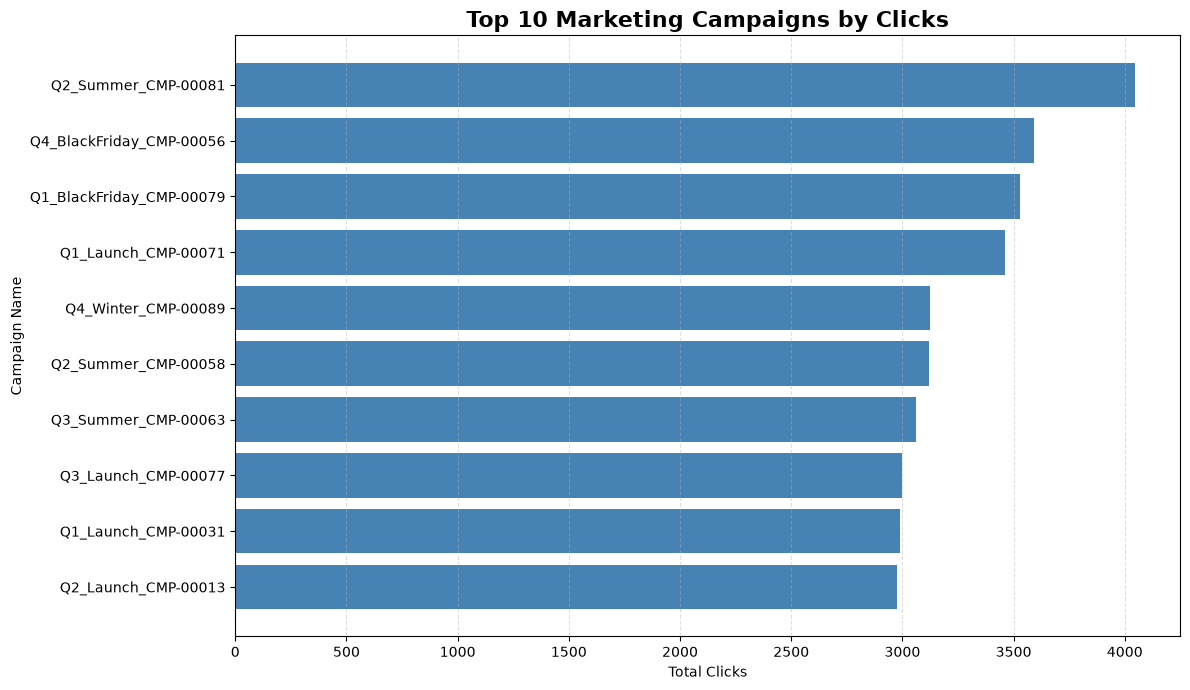

In [13]:

# Step 1: Group campaigns and calculate clicks

campaign_clicks = df.groupby(
    "Campaign_Name"
)["Clicks"].sum().sort_values(ascending=False)

# Step 2: Select top 10 campaigns

top_10_campaigns = campaign_clicks.head(10)

# Step 3: Create figure

plt.figure(figsize=(12, 7))

# Step 4: Create horizontal bar chart

plt.barh(
    top_10_campaigns.index,
    top_10_campaigns.values,
    color="steelblue"
)

# Step 5: Add title and labels

plt.title("Top 10 Marketing Campaigns by Clicks",
          fontsize=16, fontweight="bold")

plt.xlabel("Total Clicks")
plt.ylabel("Campaign Name")

# Step 6: Formatting

plt.gca().invert_yaxis()

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

# Step 7: Save chart

plt.savefig("01_Top_10_Campaigns_by_Clicks.png",
            dpi=300, bbox_inches="tight")

# Step 8: Display chart

plt.show()


In [14]:

channel_summary = df.groupby("Channel").agg(
    Total_Impressions=("Impressions", "sum"),
    Total_Clicks=("Clicks", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Total_Spend=("Spend", "sum")
)

channel_summary


,Total_Impressions,Total_Clicks,Total_Conversions,Total_Spend
Channel,,,,
Email,1527175,42757,4414.0,59858.83
Facebook,535112,19082,1707.0,22279.68
Google Ads,1139198,31677,3227.0,43556.25
Instagram,1034011,25288,2838.0,31868.60
TikTok,807745,23852,2791.0,32410.60
Unknown,196917,6429,926.0,4306.43


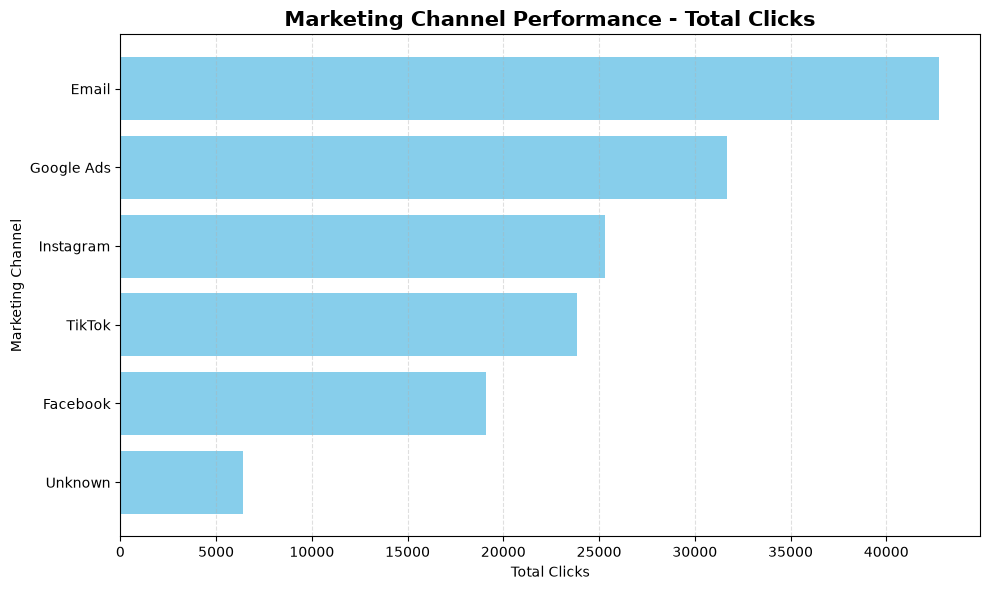

In [16]:

# Sort channels by total clicks

channel_clicks = channel_summary[
    "Total_Clicks"
].sort_values(ascending=True)

# Create figure

plt.figure(figsize=(10, 6))

# Create horizontal bar chart

plt.barh(
    channel_clicks.index,
    channel_clicks.values,
    color="skyblue"
)

# Add title and labels

plt.title("Marketing Channel Performance - Total Clicks",
          fontsize=15, fontweight="bold")

plt.xlabel("Total Clicks")
plt.ylabel("Marketing Channel")

# Add grid

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save visualization

plt.savefig("02_Channel_Performance_Clicks.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [17]:

# Calculate channel-wise CTR

channel_summary["CTR_%"] = (
    channel_summary["Total_Clicks"] /
    channel_summary["Total_Impressions"]
) * 100

# Display result

channel_summary[["Total_Clicks",
                 "Total_Impressions",
                 "CTR_%"]]


,Total_Clicks,Total_Impressions,CTR_%
Channel,,,
Email,42757,1527175,2.799745
Facebook,19082,535112,3.565982
Google Ads,31677,1139198,2.780640
Instagram,25288,1034011,2.445622
TikTok,23852,807745,2.952912
Unknown,6429,196917,3.264827


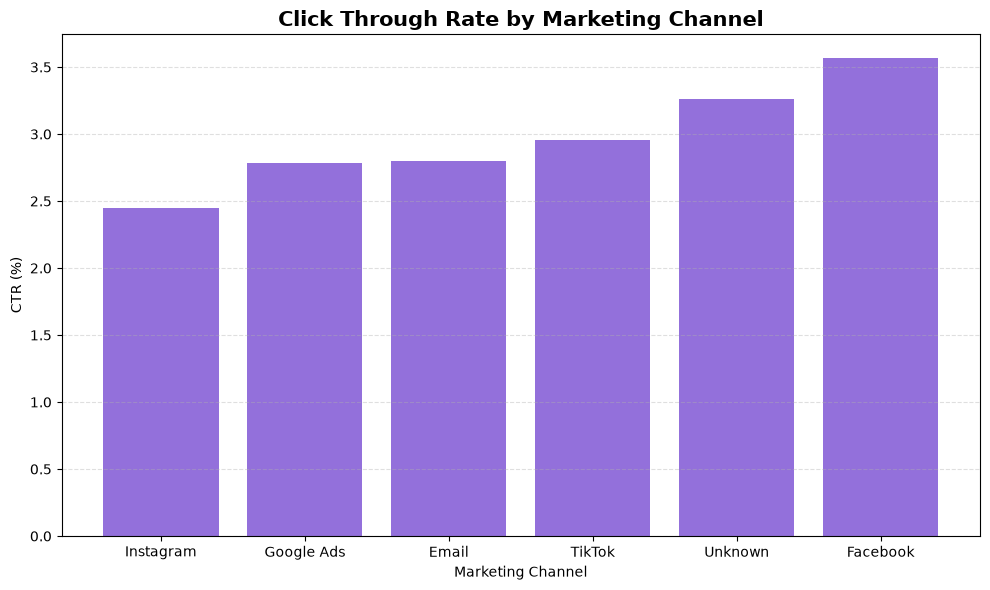

In [18]:

# Sort channels by CTR

ctr_data = channel_summary["CTR_%"].sort_values()

# Create figure

plt.figure(figsize=(10, 6))

# Create bar chart

plt.bar(
    ctr_data.index,
    ctr_data.values,
    color="mediumpurple"
)

# Add title and labels

plt.title("Click Through Rate by Marketing Channel",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Channel")
plt.ylabel("CTR (%)")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("03_Channel_Wise_CTR.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [19]:

# Keep only records with known conversions

valid_data = df.dropna(subset=["Conversions"])

# Group valid records by channel

conversion_summary = valid_data.groupby("Channel").agg(
    Total_Conversions=("Conversions", "sum"),
    Total_Clicks=("Clicks", "sum")
)

# Calculate conversion rate

conversion_summary["Conversion_Rate_%"] = (
    conversion_summary["Total_Conversions"] /
    conversion_summary["Total_Clicks"].replace(0, np.nan)
) * 100

# Display results

conversion_summary


,Total_Conversions,Total_Clicks,Conversion_Rate_%
Channel,,,
Email,4414.0,40008,11.032793
Facebook,1707.0,14177,12.040629
Google Ads,3227.0,27480,11.743086
Instagram,2838.0,22645,12.532568
TikTok,2791.0,23852,11.701325
Unknown,926.0,6429,14.403484


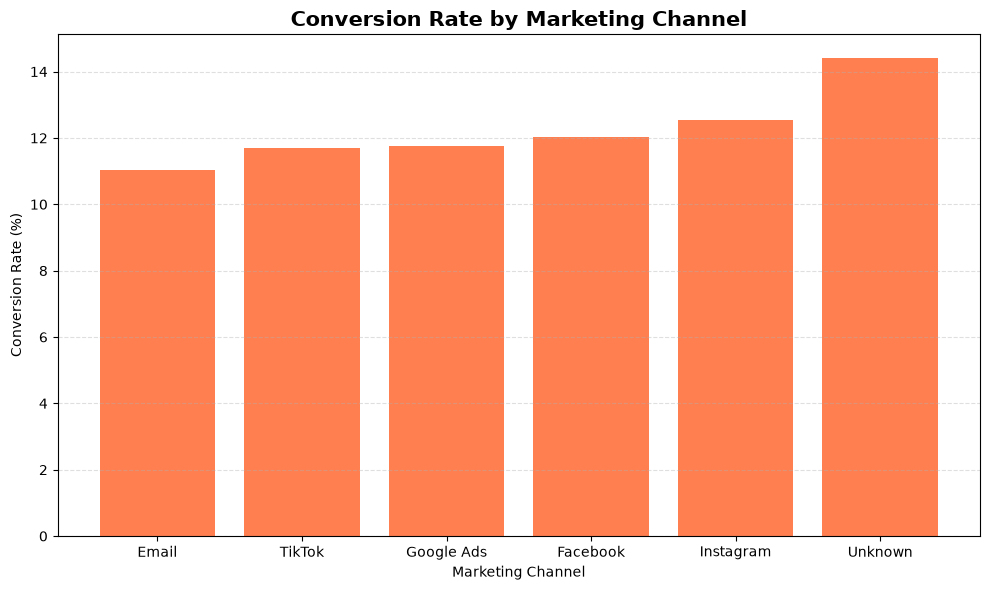

In [20]:

conversion_data = conversion_summary[
    "Conversion_Rate_%"
].sort_values()

plt.figure(figsize=(10, 6))

plt.bar(
    conversion_data.index,
    conversion_data.values,
    color="coral"
)

plt.title("Conversion Rate by Marketing Channel",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("04_Channel_Wise_Conversion_Rate.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [21]:

# Calculate channel-wise CPC and CPM

cost_summary = df.groupby("Channel").agg(
    Total_Spend=("Spend", "sum"),
    Total_Clicks=("Clicks", "sum"),
    Total_Impressions=("Impressions", "sum")
)

# Calculate CPC

cost_summary["CPC"] = (
    cost_summary["Total_Spend"] /
    cost_summary["Total_Clicks"].replace(0, np.nan)
)

# Calculate CPM

cost_summary["CPM"] = (
    cost_summary["Total_Spend"] /
    cost_summary["Total_Impressions"].replace(0, np.nan)
) * 1000

cost_summary


,Total_Spend,Total_Clicks,Total_Impressions,CPC,CPM
Channel,,,,,
Email,59858.83,42757,1527175,1.399977,39.195790
Facebook,22279.68,19082,535112,1.167576,41.635545
Google Ads,43556.25,31677,1139198,1.375012,38.234135
Instagram,31868.60,25288,1034011,1.260226,30.820368
TikTok,32410.60,23852,807745,1.358821,40.124792
Unknown,4306.43,6429,196917,0.669844,21.869265


In [22]:

# Select records with known conversions

valid_cost_data = df.dropna(subset=["Conversions"])

# Group by channel

cpa_summary = valid_cost_data.groupby("Channel").agg(
    Valid_Spend=("Spend", "sum"),
    Total_Conversions=("Conversions", "sum")
)

# Calculate CPA

cpa_summary["CPA"] = (
    cpa_summary["Valid_Spend"] /
    cpa_summary["Total_Conversions"].replace(0, np.nan)
)

cpa_summary


,Valid_Spend,Total_Conversions,CPA
Channel,,,
Email,55790.54,4414.0,12.639452
Facebook,16734.35,1707.0,9.803368
Google Ads,37547.01,3227.0,11.635268
Instagram,29171.57,2838.0,10.278918
TikTok,32410.60,2791.0,11.612540
Unknown,4306.43,926.0,4.650572


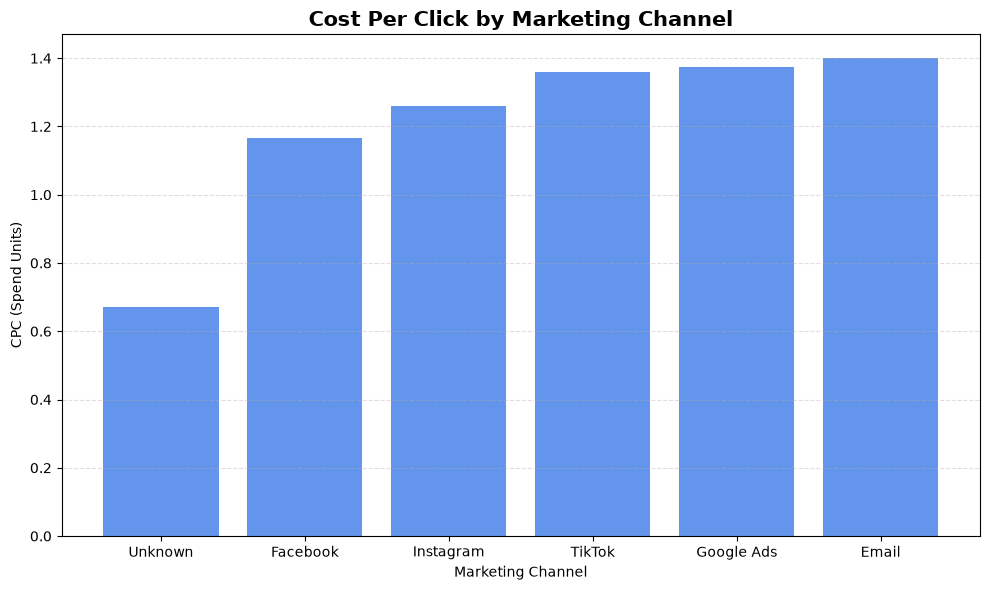

In [23]:

cpc_data = cost_summary["CPC"].sort_values()

plt.figure(figsize=(10, 6))

plt.bar(
    cpc_data.index,
    cpc_data.values,
    color="cornflowerblue"
)

plt.title("Cost Per Click by Marketing Channel",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Channel")
plt.ylabel("CPC (Spend Units)")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("05_CPC_by_Channel.png",
            dpi=300, bbox_inches="tight")

plt.show()


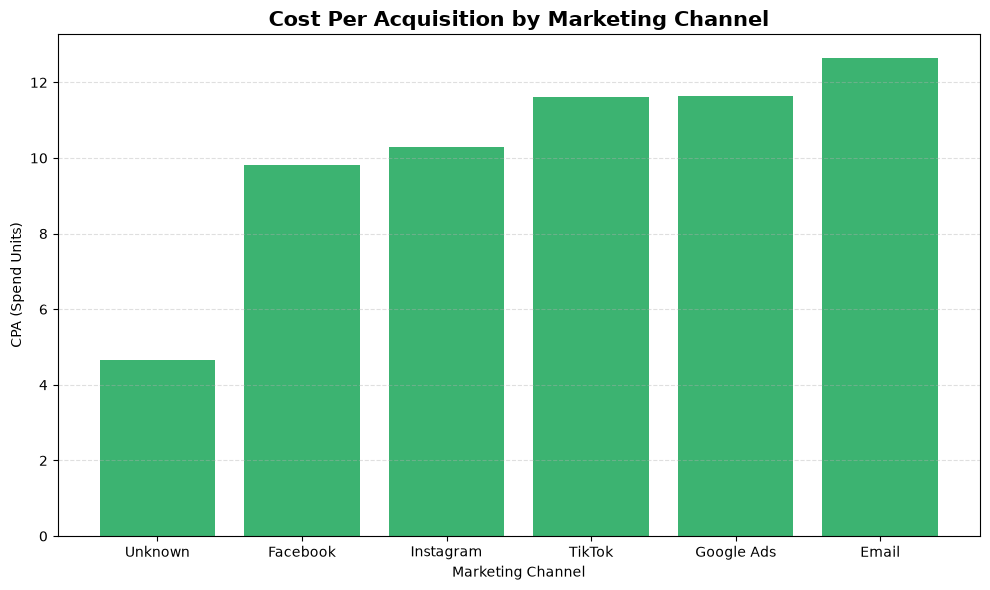

In [24]:

cpa_data = cpa_summary["CPA"].dropna().sort_values()

plt.figure(figsize=(10, 6))

plt.bar(
    cpa_data.index,
    cpa_data.values,
    color="mediumseagreen"
)

plt.title("Cost Per Acquisition by Marketing Channel",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Channel")
plt.ylabel("CPA (Spend Units)")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("06_CPA_by_Channel.png",
            dpi=300, bbox_inches="tight")

plt.show()


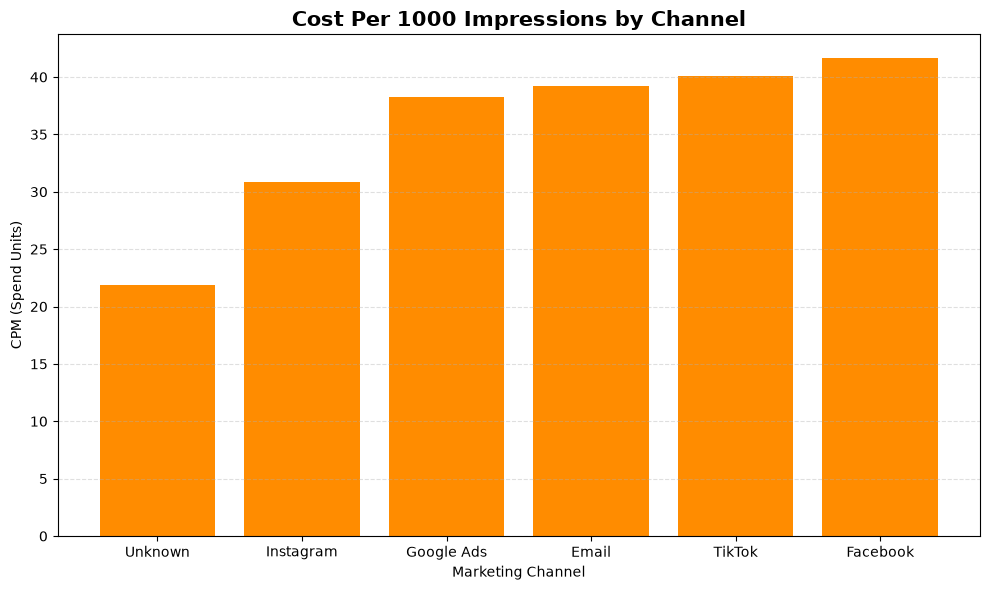

In [25]:

cpm_data = cost_summary["CPM"].sort_values()

plt.figure(figsize=(10, 6))

plt.bar(
    cpm_data.index,
    cpm_data.values,
    color="darkorange"
)

plt.title("Cost Per 1000 Impressions by Channel",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Channel")
plt.ylabel("CPM (Spend Units)")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("07_CPM_by_Channel.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [26]:

# Convert Start_Date into datetime

df["Start_Date"] = pd.to_datetime(
    df["Start_Date"],
    errors="coerce",
    format="mixed"
)

# Check the data type

df["Start_Date"].dtype


dtype('<M8[us]')

In [27]:

# Extract month and year

df["Start_Month"] = df["Start_Date"].dt.to_period("M")

# Display first 10 records

df[["Campaign_Name", "Start_Date", "Start_Month"]].head(10)


,Campaign_Name,Start_Date,Start_Month
0,Q4_Summer_CMP-00001,2023-11-24,2023-11
1,Q1_Launch_CMP-00002,2023-06-05,2023-06
2,Q3_Winter_CMP-00003,2023-12-13,2023-12
3,Q1_BlackFriday_CMP-00004,2023-10-30,2023-10
4,Q2_Winter_CMP-00005,2023-04-22,2023-04
5,Q4_BlackFriday_CMP-00006,2023-10-15,2023-10
6,Q3_Launch_CMP-00007,2023-07-10,2023-07
7,Q4_Launch_CMP-00008,2023-05-23,2023-05
8,Q4_BlackFriday_CMP-00009,2023-03-23,2023-03
9,Q2_Winter_CMP-00010,2023-03-21,2023-03


In [28]:

# Group campaigns by starting month

monthly_summary = df.groupby("Start_Month").agg(
    Total_Impressions=("Impressions", "sum"),
    Total_Clicks=("Clicks", "sum"),
    Total_Spend=("Spend", "sum"),
    Total_Conversions=(
        "Conversions",
        lambda x: x.sum(min_count=1)
    )
)

# Display monthly summary

monthly_summary


,Total_Impressions,Total_Clicks,Total_Spend,Total_Conversions
Start_Month,,,,
2023-01,207046,5458,7317.57,220.0
2023-02,681846,19665,25916.56,2185.0
2023-03,294533,7885,9281.08,641.0
2023-04,463275,13243,17126.96,1873.0
2023-05,421933,11927,15673.82,1290.0
2023-06,262750,7784,11513.78,866.0
2023-07,374806,12112,15640.08,1457.0
2023-08,365117,11077,18817.14,1402.0
2023-09,606119,18408,17470.74,1774.0


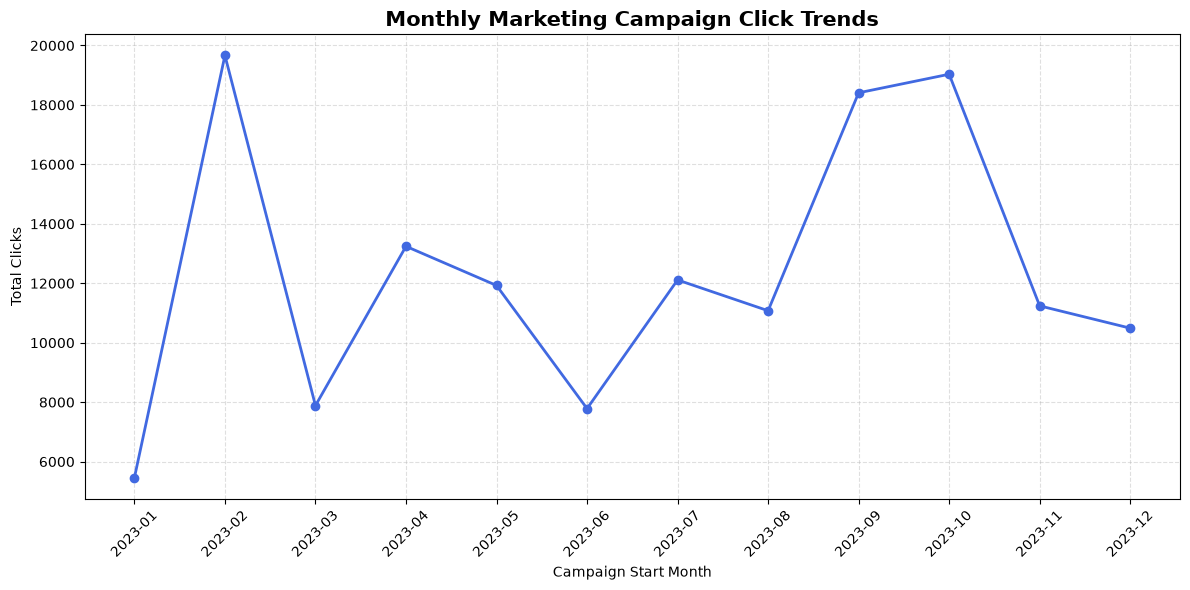

In [29]:

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_summary.index.astype(str),
    monthly_summary["Total_Clicks"],
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("Monthly Marketing Campaign Click Trends",
          fontsize=15, fontweight="bold")

plt.xlabel("Campaign Start Month")
plt.ylabel("Total Clicks")

plt.xticks(rotation=45)

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("08_Monthly_Click_Trends.png",
            dpi=300, bbox_inches="tight")

plt.show()


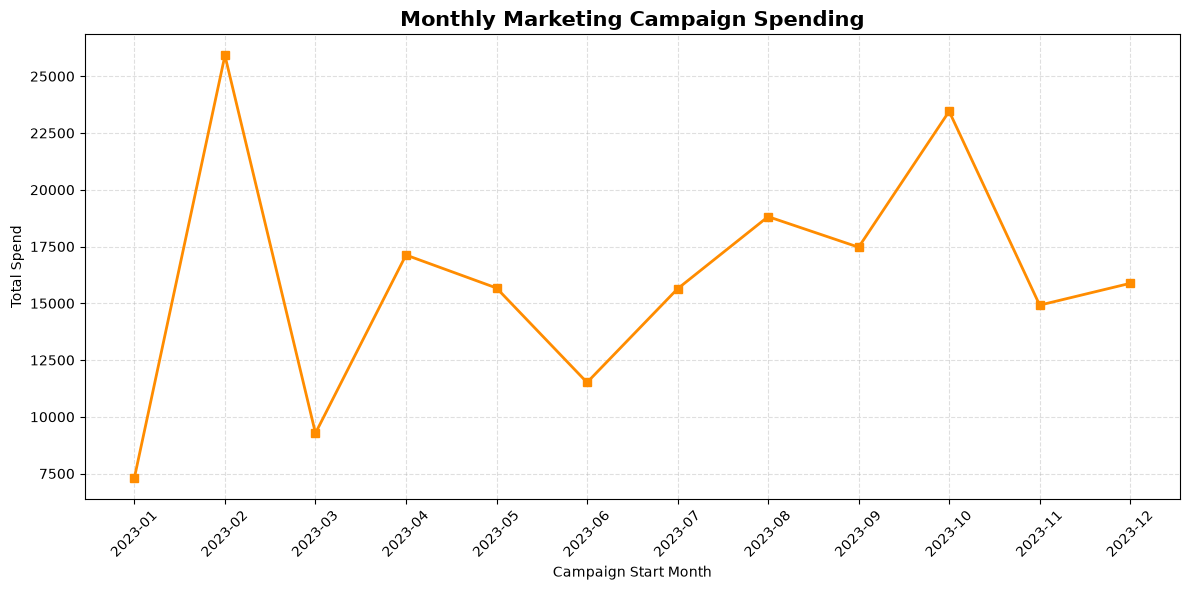

In [30]:

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_summary.index.astype(str),
    monthly_summary["Total_Spend"],
    marker="s",
    linewidth=2,
    color="darkorange"
)

plt.title("Monthly Marketing Campaign Spending",
          fontsize=15, fontweight="bold")

plt.xlabel("Campaign Start Month")
plt.ylabel("Total Spend")

plt.xticks(rotation=45)

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("09_Monthly_Spend_Trends.png",
            dpi=300, bbox_inches="tight")

plt.show()


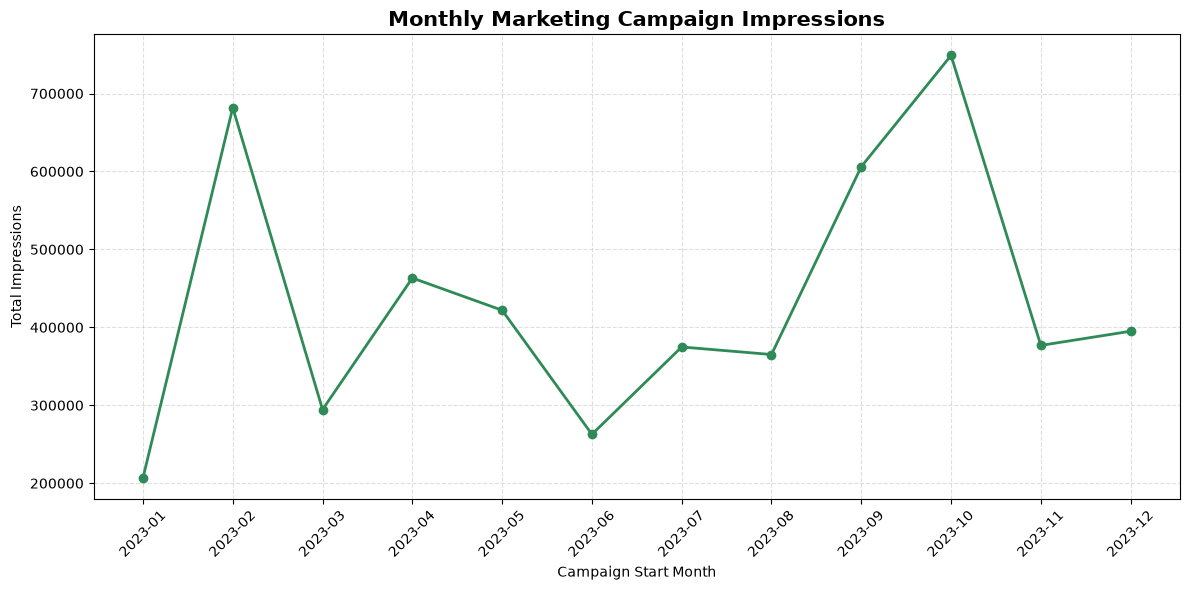

In [31]:

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_summary.index.astype(str),
    monthly_summary["Total_Impressions"],
    marker="o",
    linewidth=2,
    color="seagreen"
)

plt.title("Monthly Marketing Campaign Impressions",
          fontsize=15, fontweight="bold")

plt.xlabel("Campaign Start Month")
plt.ylabel("Total Impressions")

plt.xticks(rotation=45)

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("10_Monthly_Impressions_Trends.png",
            dpi=300, bbox_inches="tight")

plt.show()


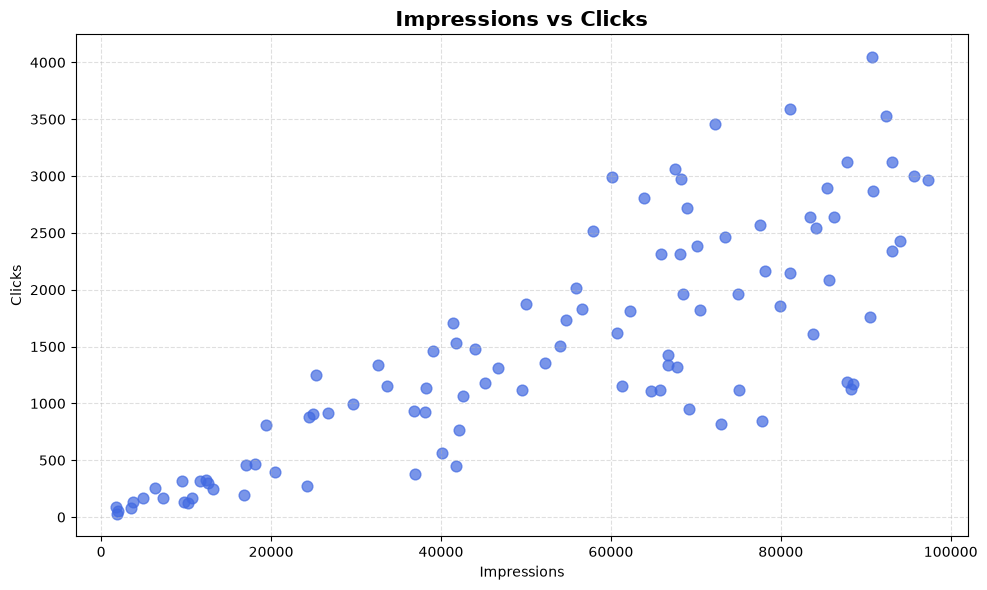

In [32]:

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Impressions"],
    df["Clicks"],
    color="royalblue",
    alpha=0.7,
    s=60
)

plt.title("Impressions vs Clicks",
          fontsize=15, fontweight="bold")

plt.xlabel("Impressions")
plt.ylabel("Clicks")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("11_Impressions_vs_Clicks.png",
            dpi=300, bbox_inches="tight")

plt.show()


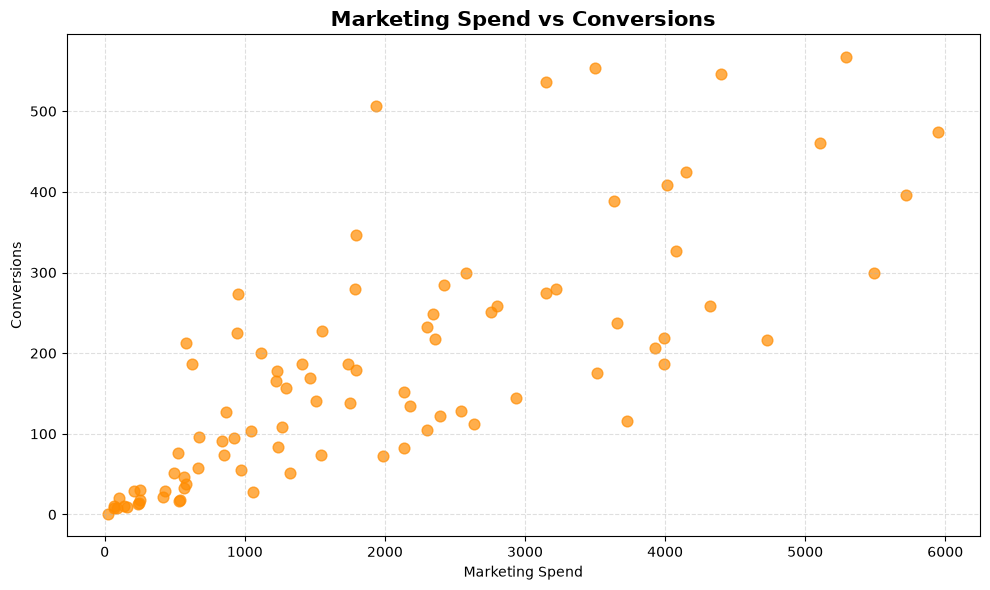

In [33]:

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Spend"],
    df["Conversions"],
    color="darkorange",
    alpha=0.7,
    s=60
)

plt.title("Marketing Spend vs Conversions",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Spend")
plt.ylabel("Conversions")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("12_Spend_vs_Conversions.png",
            dpi=300, bbox_inches="tight")

plt.show()


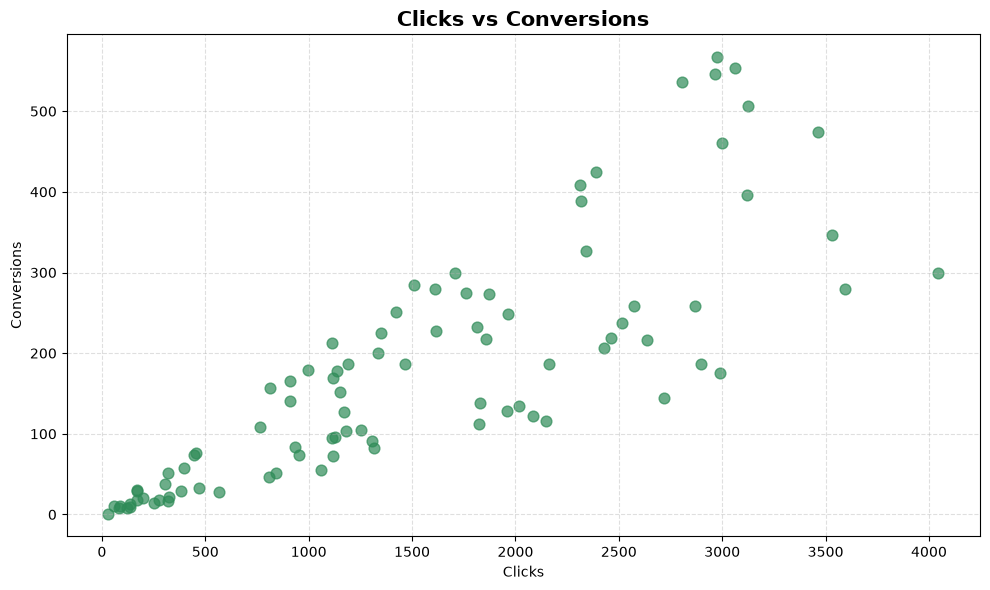

In [34]:

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Clicks"],
    df["Conversions"],
    color="seagreen",
    alpha=0.7,
    s=60
)

plt.title("Clicks vs Conversions",
          fontsize=15, fontweight="bold")

plt.xlabel("Clicks")
plt.ylabel("Conversions")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("13_Clicks_vs_Conversions.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [36]:

correlation_data = df[
    ["Impressions", "Clicks", "Spend", "Conversions"]
]

correlation_matrix = correlation_data.corr(
    method="pearson"
)

correlation_matrix


,Impressions,Clicks,Spend,Conversions
Impressions,1.000000,0.812261,0.714558,0.654955
Clicks,0.812261,1.000000,0.871589,0.820459
Spend,0.714558,0.871589,1.000000,0.768063
Conversions,0.654955,0.820459,0.768063,1.000000


In [37]:

# Select numerical columns

numeric_data = df.select_dtypes(include="number")

# Calculate correlation

correlation_matrix = numeric_data.corr(
    method="pearson"
)

# Display correlation matrix

correlation_matrix


,Impressions,Clicks,Spend,Conversions,Campaign_Duration_Days,CTR_%,Conversion_Rate_%,Calculated_CTR_%,Calculated_Conversion_Rate_%,CPC,CPA,CPM
Impressions,1.000000,0.812261,0.714558,0.654955,-0.094929,0.028834,0.043380,0.028834,0.043380,-0.009282,-0.034351,0.006883
Clicks,0.812261,1.000000,0.871589,0.820459,-0.062710,0.532240,0.064453,0.532240,0.064453,-0.015813,-0.077068,0.372613
Spend,0.714558,0.871589,1.000000,0.768063,-0.069592,0.457584,0.111920,0.457584,0.111920,0.391818,0.109940,0.611217
Conversions,0.654955,0.820459,0.768063,1.000000,0.025754,0.491088,0.521708,0.491088,0.521708,0.074443,-0.382568,0.421145
Campaign_Duration_Days,-0.094929,-0.062710,-0.069592,0.025754,1.000000,-0.046979,-0.006965,-0.046979,-0.006965,-0.094732,-0.015794,-0.088164
CTR_%,0.028834,0.532240,0.457584,0.491088,-0.046979,1.000000,0.139741,1.000000,0.139741,0.003909,-0.142232,0.748645
Conversion_Rate_%,0.043380,0.064453,0.111920,0.521708,-0.006965,0.139741,1.000000,0.139741,1.000000,0.144219,-0.720260,0.212681
Calculated_CTR_%,0.028834,0.532240,0.457584,0.491088,-0.046979,1.000000,0.139741,1.000000,0.139741,0.003909,-0.142232,0.748645
Calculated_Conversion_Rate_%,0.043380,0.064453,0.111920,0.521708,-0.006965,0.139741,1.000000,0.139741,1.000000,0.144219,-0.720260,0.212681
CPC,-0.009282,-0.015813,0.391818,0.074443,-0.094732,0.003909,0.144219,0.003909,0.144219,1.000000,0.480536,0.616059


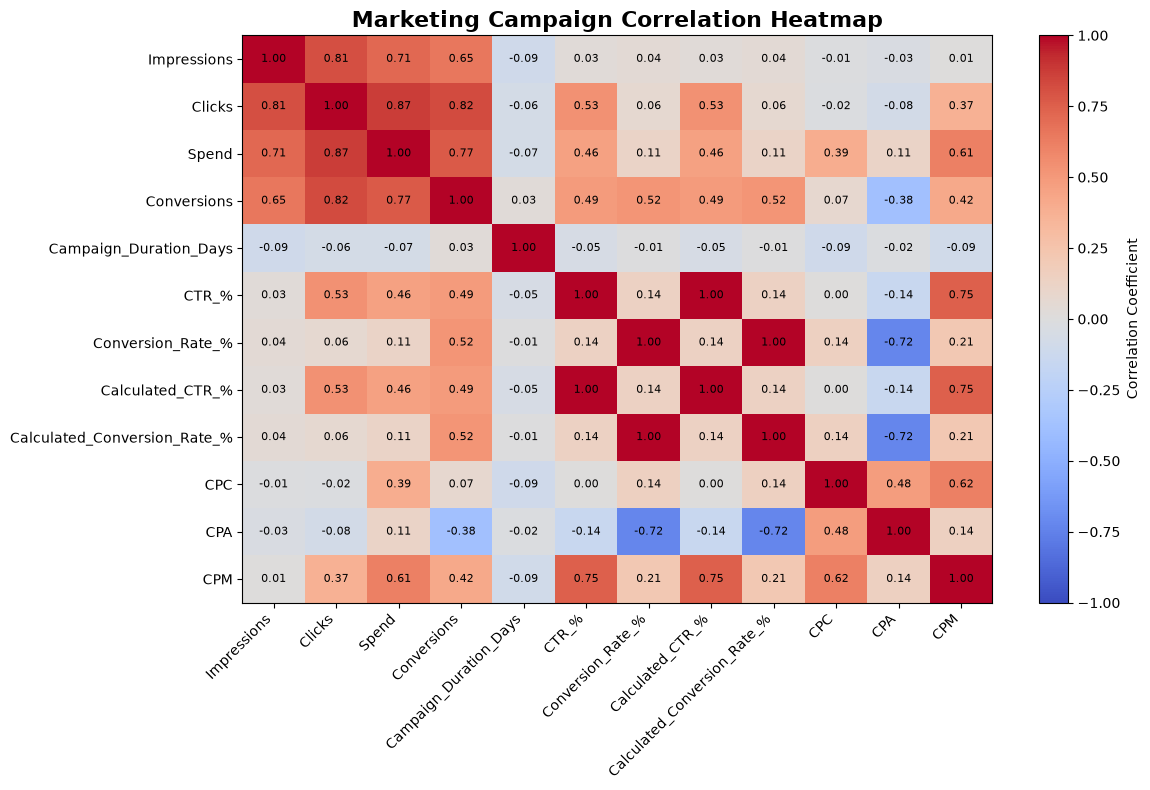

In [38]:

# Create figure

plt.figure(figsize=(12, 8))

# Create heatmap

heatmap = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

# Add colorbar

plt.colorbar(
    heatmap,
    label="Correlation Coefficient"
)

# Add column names

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

# Add correlation values inside cells

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):

        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

# Title

plt.title(
    "Marketing Campaign Correlation Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save visualization

plt.savefig(
    "14_Marketing_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


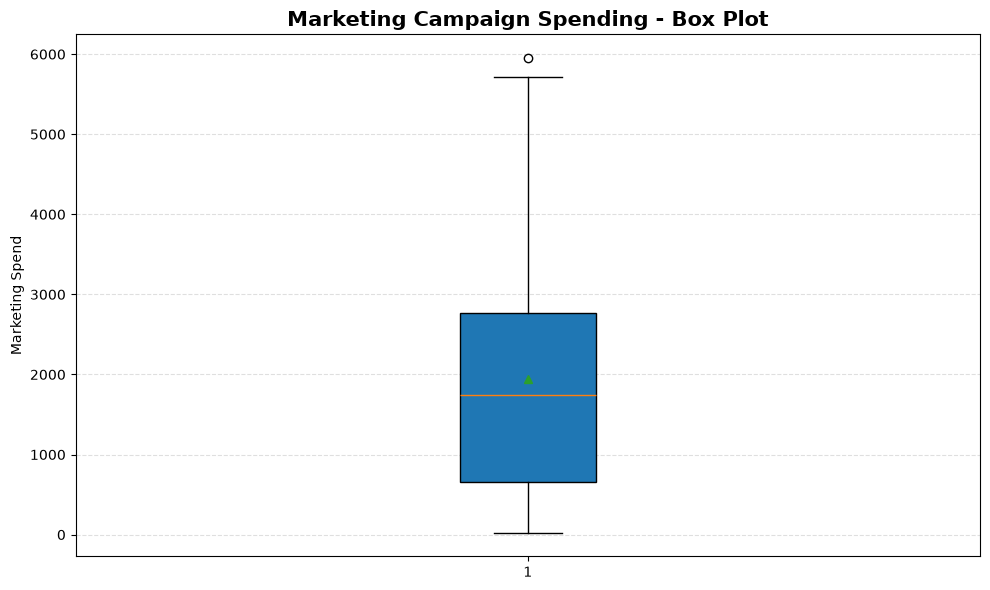

In [39]:

plt.figure(figsize=(10, 6))

plt.boxplot(
    df["Spend"].dropna(),
    patch_artist=True,
    showmeans=True
)

plt.title("Marketing Campaign Spending - Box Plot",
          fontsize=15, fontweight="bold")

plt.ylabel("Marketing Spend")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "15_Spending_Boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [40]:

# Select the Spend column

spend = df["Spend"].dropna()

# Calculate quartiles

Q1 = spend.quantile(0.25)
Q3 = spend.quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate lower and upper limits

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

# Identify outliers

outliers = spend[
    (spend < lower_limit) |
    (spend > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Outlier Values:")
print(outliers)


Q1: 657.915
Q3: 2770.3775
IQR: 2112.4625
Lower Limit: -2510.7787500000004
Upper Limit: 5939.071250000001
Outlier Values:
70    5951.42
Name: Spend, dtype: float64


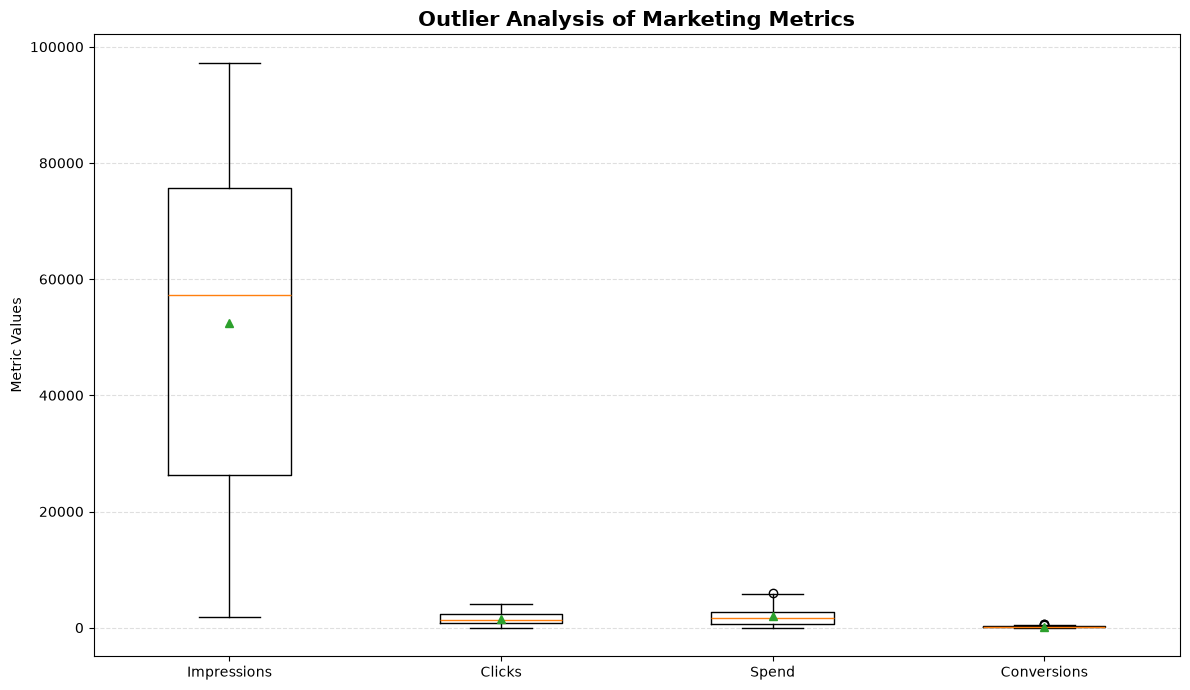

In [41]:

# Select numerical marketing metrics

metrics = [
    "Impressions",
    "Clicks",
    "Spend",
    "Conversions"
]

# Create box plots

plt.figure(figsize=(12, 7))

plt.boxplot(
    [df[col].dropna() for col in metrics],
    tick_labels=metrics,
    showmeans=True
)

plt.title("Outlier Analysis of Marketing Metrics",
          fontsize=15, fontweight="bold")

plt.ylabel("Metric Values")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "16_Marketing_Metrics_Outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [42]:

outlier_counts = {}

for col in metrics:

    data = df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (data < lower) | (data > upper)
    ).sum()

    outlier_counts[col] = count

print(pd.Series(outlier_counts, name="Outlier_Count"))


Impressions    0
Clicks         0
Spend          1
Conversions    3
Name: Outlier_Count, dtype: int64


In [43]:

# Prepare channel-wise data

grouped_data = df.groupby("Channel").agg(
    Total_Clicks=("Clicks", "sum"),
    Total_Conversions=("Conversions", "sum")
)

grouped_data


,Total_Clicks,Total_Conversions
Channel,,
Email,42757,4414.0
Facebook,19082,1707.0
Google Ads,31677,3227.0
Instagram,25288,2838.0
TikTok,23852,2791.0
Unknown,6429,926.0


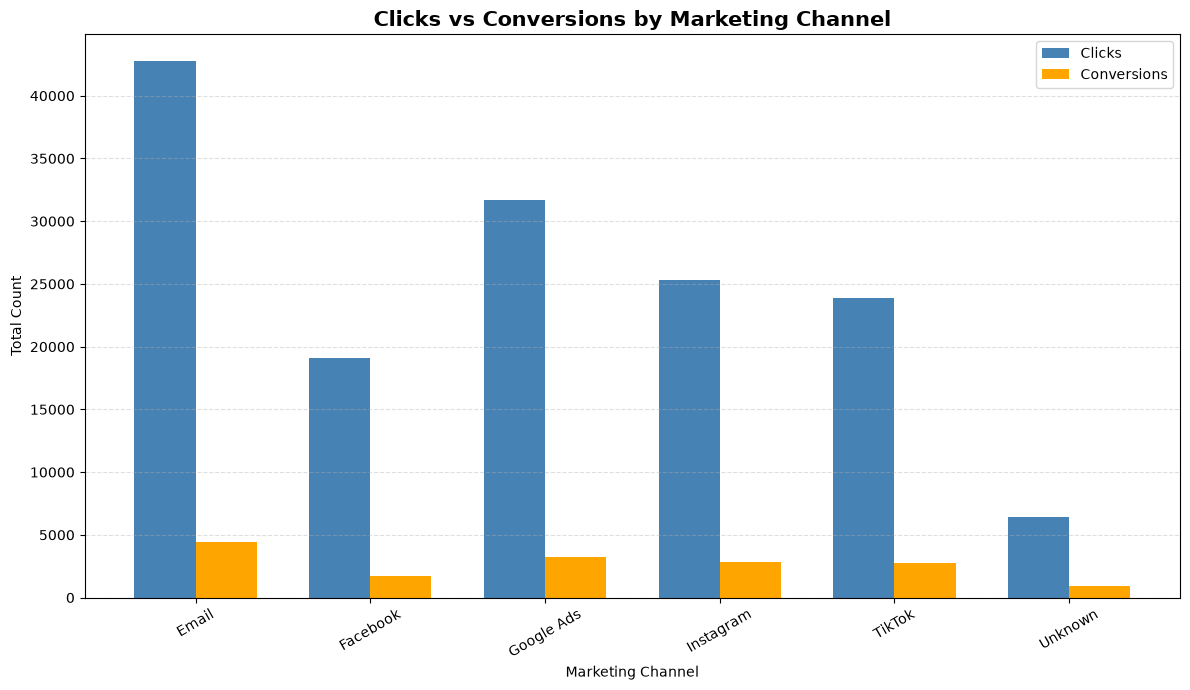

In [44]:

# Import numpy if not already imported
import numpy as np

# Create positions

x = np.arange(len(grouped_data))

# Set bar width

width = 0.35

# Create figure

plt.figure(figsize=(12, 7))

# Create two groups of bars

plt.bar(
    x - width/2,
    grouped_data["Total_Clicks"],
    width,
    label="Clicks",
    color="steelblue"
)

plt.bar(
    x + width/2,
    grouped_data["Total_Conversions"],
    width,
    label="Conversions",
    color="orange"
)

# Add labels

plt.title("Clicks vs Conversions by Marketing Channel",
          fontsize=15, fontweight="bold")

plt.xlabel("Marketing Channel")
plt.ylabel("Total Count")

plt.xticks(x, grouped_data.index, rotation=30)

plt.legend()

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "17_Clicks_vs_Conversions_Grouped_Bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


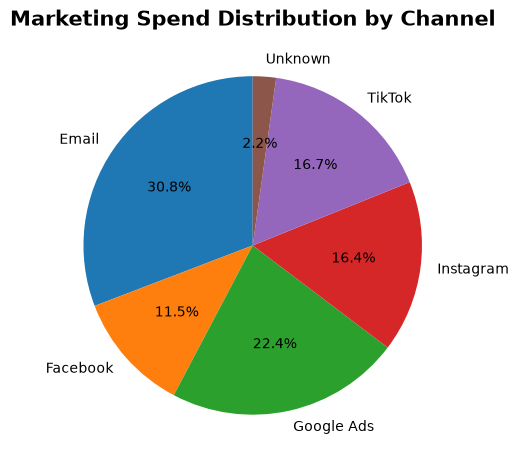

In [46]:

# Calculate channel-wise spending

spend_by_channel = df.groupby("Channel")["Spend"].sum()

# Create pie chart

plt.figure(figsize=(5, 5))

plt.pie(
    spend_by_channel,
    labels=spend_by_channel.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=False
)

plt.title(
    "Marketing Spend Distribution by Channel",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "18_Marketing_Spend_Pie_Chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


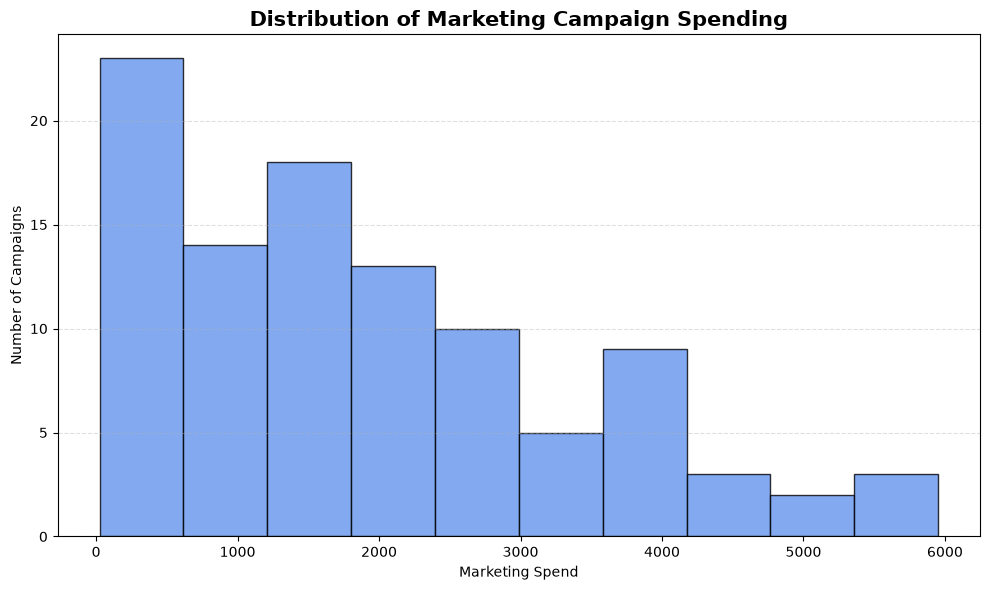

In [47]:

# Select valid spending values

spend_data = df["Spend"].dropna()

# Create histogram

plt.figure(figsize=(10, 6))

plt.hist(
    spend_data,
    bins=10,
    color="cornflowerblue",
    edgecolor="black",
    alpha=0.8
)

# Add title and labels

plt.title(
    "Distribution of Marketing Campaign Spending",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Marketing Spend")
plt.ylabel("Number of Campaigns")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "19_Marketing_Spend_Histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [48]:

# Select records with available conversions

bubble_data = df.dropna(
    subset=["Clicks", "Conversions", "Spend"]
).copy()

# Display selected columns

bubble_data[[
    "Campaign_Name",
    "Channel",
    "Clicks",
    "Conversions",
    "Spend"
]].head(10)


,Campaign_Name,Channel,Clicks,Conversions,Spend
0,Q4_Summer_CMP-00001,TikTok,197,20.0,102.82
1,Q1_Launch_CMP-00002,Facebook,30,1.0,24.33
2,Q3_Winter_CMP-00003,Email,843,51.0,1323.39
3,Q1_BlackFriday_CMP-00004,TikTok,2019,135.0,2180.38
4,Q2_Winter_CMP-00005,Facebook,169,30.0,252.44
6,Q3_Launch_CMP-00007,Facebook,1135,178.0,1232.76
7,Q4_Launch_CMP-00008,Instagram,1173,127.0,865.70
8,Q4_BlackFriday_CMP-00009,Google Ads,1179,104.0,1046.18
10,Q4_Launch_CMP-00011,Instagram,455,76.0,523.13
11,Q4_Launch_CMP-00012,Google Ads,763,109.0,1267.69


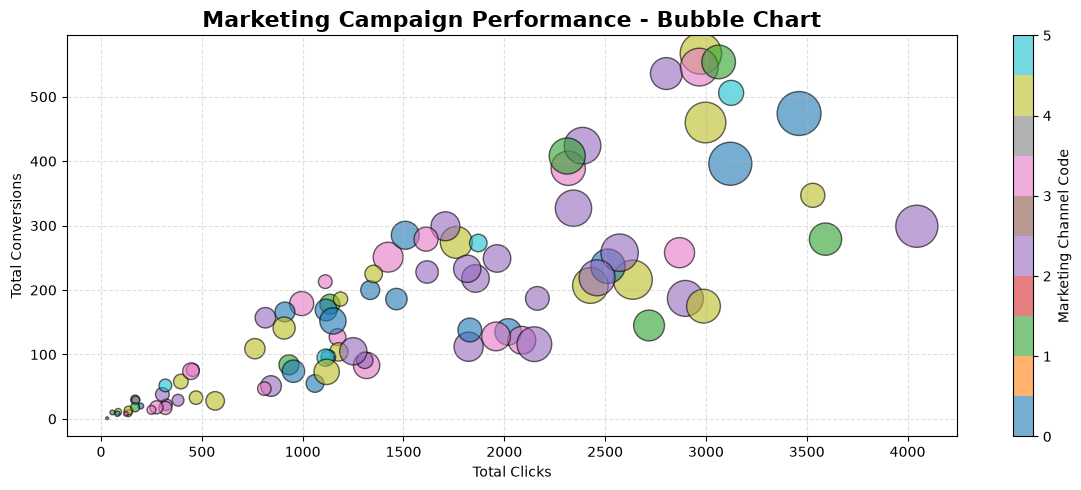

In [51]:

plt.figure(figsize=(12, 5))

# Scale bubble sizes using marketing spend

bubble_sizes = (
    bubble_data["Spend"] /
    bubble_data["Spend"].max()
) * 1000

# Convert channel names into numeric colour codes

channel_codes = pd.factorize(
    bubble_data["Channel"]
)[0]

# Create bubble chart

scatter = plt.scatter(
    bubble_data["Clicks"],
    bubble_data["Conversions"],
    s=bubble_sizes,
    c=channel_codes,
    cmap="tab10",
    alpha=0.6,
    edgecolors="black"
)

# Add colorbar

cbar = plt.colorbar(scatter)

cbar.set_label("Marketing Channel Code")

# Add labels

plt.title(
    "Marketing Campaign Performance - Bubble Chart",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Clicks")
plt.ylabel("Total Conversions")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "20_Marketing_Bubble_Chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


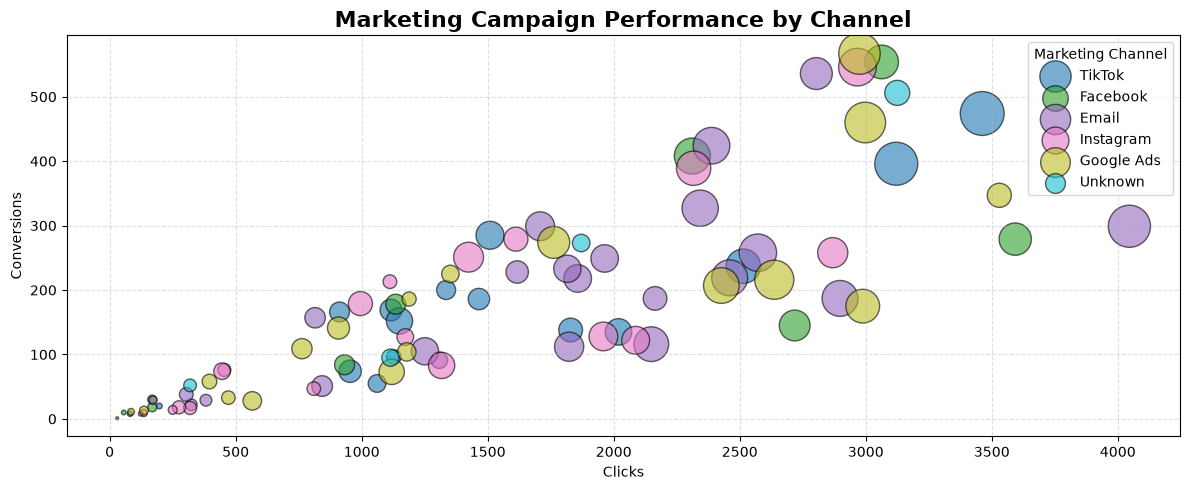

In [53]:

plt.figure(figsize=(12, 5))

channels = bubble_data["Channel"].unique()

colors = plt.cm.tab10(
    np.linspace(0, 1, len(channels))
)

for channel, color in zip(channels, colors):

    channel_df = bubble_data[
        bubble_data["Channel"] == channel
    ]

    sizes = (
        channel_df["Spend"] /
        bubble_data["Spend"].max()
    ) * 1000

    plt.scatter(
        channel_df["Clicks"],
        channel_df["Conversions"],
        s=sizes,
        color=color,
        alpha=0.6,
        edgecolors="black",
        label=channel
    )

plt.title(
    "Marketing Campaign Performance by Channel",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Clicks")
plt.ylabel("Conversions")

plt.legend(title="Marketing Channel")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "21_Professional_Marketing_Bubble_Chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [54]:

top_campaigns = bubble_data.sort_values(
    by="Conversions",
    ascending=False
).head(10)

top_campaigns[[
    "Campaign_Name",
    "Channel",
    "Clicks",
    "Conversions",
    "Spend"
]]


,Campaign_Name,Channel,Clicks,Conversions,Spend
12,Q2_Launch_CMP-00013,Google Ads,2975,567.0,5292.16
62,Q3_Summer_CMP-00063,Facebook,3063,554.0,3502.47
42,Q2_Summer_CMP-00043,Instagram,2967,546.0,4397.28
16,Q1_Winter_CMP-00017,Email,2804,536.0,3147.37
88,Q4_Winter_CMP-00089,Unknown,3125,506.0,1938.54
70,Q1_Launch_CMP-00071,TikTok,3462,474.0,5951.42
76,Q3_Launch_CMP-00077,Google Ads,2998,460.0,5102.66
39,Q4_BlackFriday_CMP-00040,Email,2388,424.0,4152.44
58,Q3_Launch_CMP-00059,Facebook,2312,408.0,4014.77
57,Q2_Summer_CMP-00058,TikTok,3121,396.0,5719.84


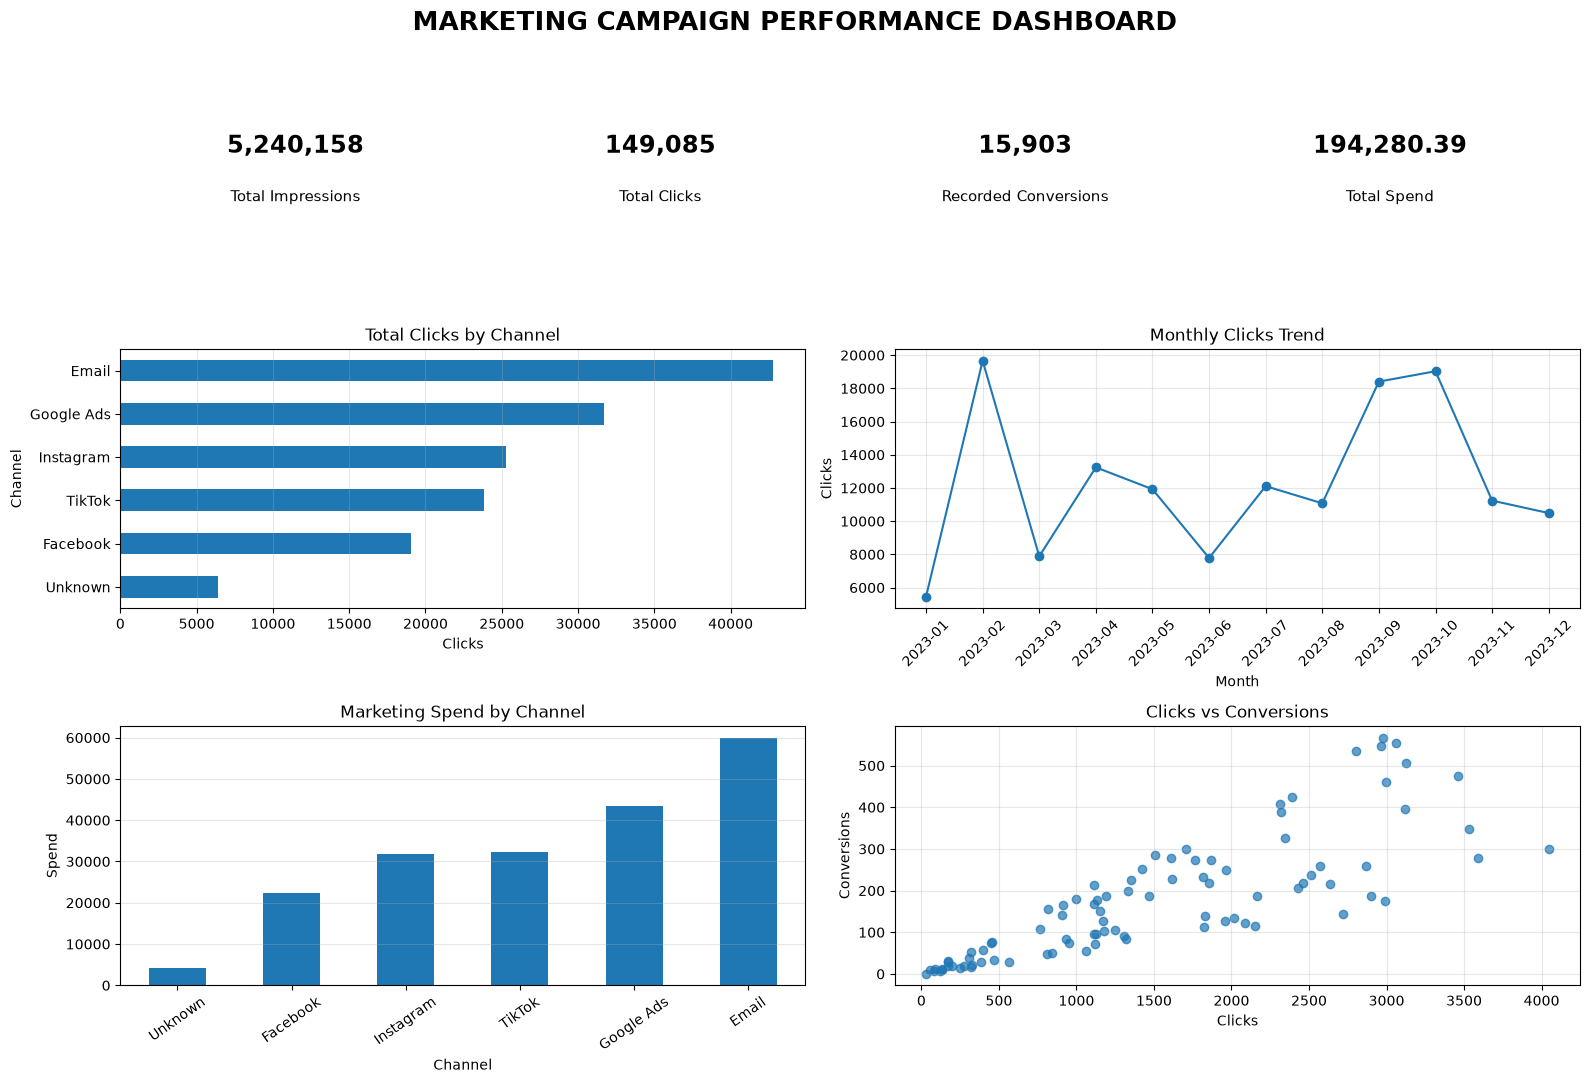

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare data
dashboard_data = df.copy()

dashboard_data["Start_Date"] = pd.to_datetime(
    dashboard_data["Start_Date"], errors="coerce"
)

# Calculate KPIs
total_impressions = dashboard_data["Impressions"].sum()
total_clicks = dashboard_data["Clicks"].sum()
total_conversions = dashboard_data["Conversions"].sum(min_count=1)
total_spend = dashboard_data["Spend"].sum()

ctr = (total_clicks / total_impressions * 100
       if total_impressions != 0 else np.nan)

# Prepare channel summary
channel_summary = dashboard_data.groupby("Channel").agg(
    Total_Clicks=("Clicks", "sum"),
    Total_Spend=("Spend", "sum")
)

# Prepare monthly summary
monthly_summary = (
    dashboard_data.dropna(subset=["Start_Date"])
    .assign(Month=lambda x: x["Start_Date"].dt.to_period("M"))
    .groupby("Month")["Clicks"]
    .sum()
)

# Prepare scatter plot data
scatter_data = dashboard_data.dropna(
    subset=["Clicks", "Conversions"]
)

# Create dashboard
fig = plt.figure(figsize=(16, 11))

gs = fig.add_gridspec(
    3, 2,
    height_ratios=[0.7, 1.5, 1.5]
)

fig.suptitle(
    "MARKETING CAMPAIGN PERFORMANCE DASHBOARD",
    fontsize=19,
    fontweight="bold"
)

# KPI section
kpi_ax = fig.add_subplot(gs[0, :])
kpi_ax.axis("off")

kpis = [
    ("Total Impressions", f"{total_impressions:,.0f}"),
    ("Total Clicks", f"{total_clicks:,.0f}"),
    ("Recorded Conversions", f"{total_conversions:,.0f}"),
    ("Total Spend", f"{total_spend:,.2f}")
]

positions = [0.12, 0.37, 0.62, 0.87]

for (label, value), x in zip(kpis, positions):
    kpi_ax.text(
        x, 0.65, value,
        ha="center",
        fontsize=17,
        fontweight="bold"
    )
    kpi_ax.text(
        x, 0.25, label,
        ha="center",
        fontsize=11
    )

# Chart 1: Channel-wise clicks
ax1 = fig.add_subplot(gs[1, 0])

channel_summary["Total_Clicks"].sort_values().plot(
    kind="barh",
    ax=ax1
)

ax1.set_title("Total Clicks by Channel")
ax1.set_xlabel("Clicks")
ax1.set_ylabel("Channel")
ax1.grid(axis="x", alpha=0.3)

# Chart 2: Monthly clicks
ax2 = fig.add_subplot(gs[1, 1])

ax2.plot(
    monthly_summary.index.astype(str),
    monthly_summary.values,
    marker="o"
)

ax2.set_title("Monthly Clicks Trend")
ax2.set_xlabel("Month")
ax2.set_ylabel("Clicks")
ax2.tick_params(axis="x", rotation=45)
ax2.grid(alpha=0.3)

# Chart 3: Channel-wise spend
ax3 = fig.add_subplot(gs[2, 0])

channel_summary["Total_Spend"].sort_values().plot(
    kind="bar",
    ax=ax3
)

ax3.set_title("Marketing Spend by Channel")
ax3.set_xlabel("Channel")
ax3.set_ylabel("Spend")
ax3.tick_params(axis="x", rotation=35)
ax3.grid(axis="y", alpha=0.3)

# Chart 4: Clicks vs conversions
ax4 = fig.add_subplot(gs[2, 1])

ax4.scatter(
    scatter_data["Clicks"],
    scatter_data["Conversions"],
    alpha=0.7
)

ax4.set_title("Clicks vs Conversions")
ax4.set_xlabel("Clicks")
ax4.set_ylabel("Conversions")
ax4.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.94])

# Save dashboard
plt.savefig(
    "22_Marketing_Performance_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "22_Marketing_Performance_Dashboard.pdf",
    bbox_inches="tight"
)

plt.show()

In [56]:
# 1. Channel with highest clicks
best_click_channel = channel_summary["Total_Clicks"].idxmax()
highest_clicks = channel_summary["Total_Clicks"].max()

print("Channel with highest clicks:", best_click_channel)
print("Total clicks:", highest_clicks)


# 2. Channel with highest spending
highest_spend_channel = channel_summary["Total_Spend"].idxmax()
highest_spend = channel_summary["Total_Spend"].max()

print("\nChannel with highest spend:", highest_spend_channel)
print("Total spend:", highest_spend)


# 3. Month with highest clicks
if not monthly_summary.empty:
    best_month = monthly_summary.idxmax()
    monthly_clicks = monthly_summary.max()

    print("\nMonth with highest clicks:", best_month)
    print("Monthly clicks:", monthly_clicks)


# 4. Correlation between clicks and conversions
correlation = scatter_data[
    ["Clicks", "Conversions"]
].corr().iloc[0, 1]

print("\nClicks and conversions correlation:", round(correlation, 2))


# 5. Overall CTR
print("\nOverall CTR:", round(ctr, 2), "%")

Channel with highest clicks: Email
Total clicks: 42757

Channel with highest spend: Email
Total spend: 59858.83

Month with highest clicks: 2023-02
Monthly clicks: 19665

Clicks and conversions correlation: 0.82

Overall CTR: 2.85 %
